# Assignment 07: Critique, Redesign, and Explain Cardiac Rehab Charts

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [1]:
import json
from pathlib import Path

import altair as alt
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Altair:", alt.__version__)

DATA_DIR = Path("data")
PATIENTS_PATH = DATA_DIR / "rehab_patients.csv"
ATTENDANCE_PATH = DATA_DIR / "session_attendance.csv"
FOLLOWUP_PATH = DATA_DIR / "followup_goals.csv"

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
EXPLORATORY_SPEC_PATH = OUTPUT_DIR / "exploratory_spec.json"
EVIDENCE_PATH = OUTPUT_DIR / "visualization_evidence.json"
REDESIGN_PATH = OUTPUT_DIR / "critique_redesign.png"
SUPPORTING_DATA_PATH = OUTPUT_DIR / "explanatory_supporting_data.csv"
EXPLANATORY_PATH = OUTPUT_DIR / "explanatory_chart.png"
TEXT_ALTERNATIVE_PATH = OUTPUT_DIR / "explanatory_text_alternative.txt"

BLUE = "#0072B2"  # colorblind-safe blue
ORANGE = "#E69F00"  # colorblind-safe orange

print("data files found:", PATIENTS_PATH.exists() and ATTENDANCE_PATH.exists() and FOLLOWUP_PATH.exists())

NumPy: 2.3.3
pandas: 3.0.5
matplotlib: 3.11.1
Altair: 5.5.0
data files found: True


## Task 1: Explore the rehab patients with Altair

### 1.1 Load the patients and build the scatter plot

> **Checkpoint: `output/exploratory_spec.json`**
> A Vega-Lite specification with a `point` mark, `x`, `y`, `color`, and `shape` encodings, and the twelve patients embedded.

In [2]:
patients = pd.read_csv(PATIENTS_PATH)
print("shape:", patients.shape)
display(patients.dtypes)

exploratory_chart = (
    alt.Chart(patients)
    .mark_point(filled=True, size=90)
    .encode(
        x=alt.X("sessions_attended:Q", title="Sessions attended (of 36)"),
        y=alt.Y("walk_distance_m:Q", title="Six-minute walk distance (m)",
                scale=alt.Scale(zero=False)),
        color=alt.Color("program:N", title="Program"),
        shape=alt.Shape("program:N", title="Program"),
        tooltip=["patient_id:N", "program:N", "sessions_attended:Q", "walk_distance_m:Q"],
    )
    .properties(title="Sessions attended vs. six-minute walk distance at discharge, by program")
)

exploratory_chart.save(EXPLORATORY_SPEC_PATH)

exploratory_chart

shape: (12, 4)


patient_id             str
program                str
sessions_attended    int64
walk_distance_m      int64
dtype: object

alt.Chart(...)

### 1.2 Describe what the chart shows

This chart explores whether patients who attend more rehab sessions walk farther in the six-minute walk test at discharge, and whether that relationship looks different between the home-based and center-based programs. Each point is one patient, placed by how many of the 36 sessions they attended and how far they walked. Walk distance rises fairly steadily with sessions attended in both programs, from about 350 m around 10 sessions to about 430 to 460 m above 30 sessions, and the two programs follow a similar trend. With only twelve patients who chose their own program and how often to attend, this cannot show that attending more sessions causes a longer walk: healthier or more motivated patients may both attend more and walk farther, and a sample this small could show this pattern by chance.

## Task 2: Critique and redesign a misleading chart

### 2.1 Inspect the draft chart

The next cell draws a draft chart from the rehab service's dashboard. Run it and look at the chart before you start Task 2.2.

,program,quarter,attended_pct
0,Home-based,Q1,81
1,Home-based,Q2,77
2,Center-based,Q1,82
3,Center-based,Q2,80


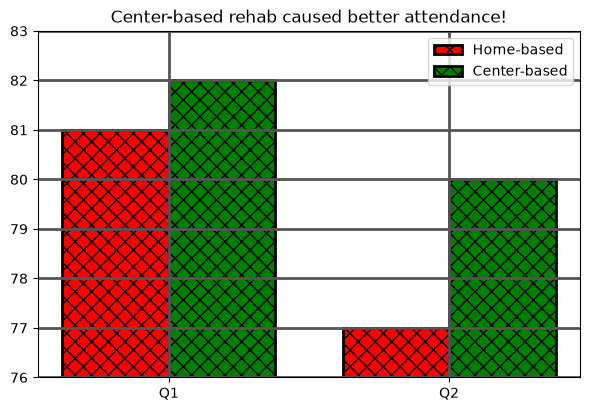

In [3]:
attendance = pd.read_csv(ATTENDANCE_PATH)
display(attendance)

quarters = ["Q1", "Q2"]
x = np.arange(len(quarters))  # [0 1]: one position per quarter
width = 0.38
home = attendance.loc[attendance["program"] == "Home-based", "attended_pct"]
center = attendance.loc[attendance["program"] == "Center-based", "attended_pct"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, home, width, label="Home-based", color="red",
       hatch="xx", edgecolor="black", linewidth=2)
ax.bar(x + width / 2, center, width, label="Center-based", color="green",
       hatch="xx", edgecolor="black", linewidth=2)
ax.set_xticks(x, quarters)
ax.set_ylim(76, 83)
ax.grid(True, linewidth=2, color="#555555")
ax.set_title("Center-based rehab caused better attendance!")
ax.legend()
plt.show()

### 2.2 Write the critique

Fill in a `problem` and a `repair` for each category, then run the cell to save the critique.

> **Checkpoint: `output/visualization_evidence.json`**
> An object with the key `critique`: a list of five entries, each with the keys `category`, `problem`, and `repair`.

In [6]:
critique = [
    {"category": "unsupported claim",
     "problem": "The title says center-based rehab 'caused' better attendance, but patients chose their program and the chart only shows four percentages, so it cannot show cause.",
     "repair": "Use a descriptive title that states what the bars show (attendance by program and quarter) without claiming a cause."},
    {"category": "truncated baseline",
     "problem": "The y-axis starts at 76, so a 1 to 3 point difference looks like a bar several times taller, exaggerating the gap between programs and quarters.",
     "repair": "Start the y-axis at 0 (0 to 100) so bar length is proportional to the value."},
    {"category": "missing unit",
     "problem": "The y-axis has no label or unit, so a reader cannot tell the numbers are percentages of scheduled sessions attended.",
     "repair": "Label the y-axis 'Scheduled sessions attended (%)' and the x-axis 'Quarter', and write each value on its bar."},
    {"category": "color-only encoding",
     "problem": "Both programs use the same 'xx' hatch and differ only by red vs. green, which colorblind readers and grayscale printouts cannot tell apart.",
     "repair": "Use a colorblind-safe pair (orange and blue) and give each program its own hatch ('..' and '//')."},
    {"category": "distracting decoration",
     "problem": "Thick black edges, dense hatching, and a heavy dark grid carry no data and pull attention away from the bar heights.",
     "repair": "Remove the thick edges and heavy grid, hide the top and right spines, and move the legend outside the plot area."},
]

for entry in critique:
    print(f"{entry['category']}: {entry['problem']}")
    print(f"    repair: {entry['repair']}")

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump({"critique": critique}, file, indent=2, ensure_ascii=False)

unsupported claim: The title says center-based rehab 'caused' better attendance, but patients chose their program and the chart only shows four percentages, so it cannot show cause.
    repair: Use a descriptive title that states what the bars show (attendance by program and quarter) without claiming a cause.
truncated baseline: The y-axis starts at 76, so a 1 to 3 point difference looks like a bar several times taller, exaggerating the gap between programs and quarters.
    repair: Start the y-axis at 0 (0 to 100) so bar length is proportional to the value.
missing unit: The y-axis has no label or unit, so a reader cannot tell the numbers are percentages of scheduled sessions attended.
    repair: Label the y-axis 'Scheduled sessions attended (%)' and the x-axis 'Quarter', and write each value on its bar.
color-only encoding: Both programs use the same 'xx' hatch and differ only by red vs. green, which colorblind readers and grayscale printouts cannot tell apart.
    repair: Use a col

### 2.3 Redesign the chart

> **Checkpoint: `output/critique_redesign.png`**
> Your redesigned chart as a PNG image.

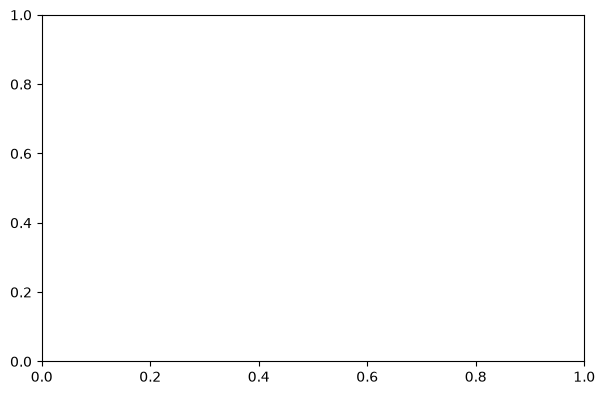

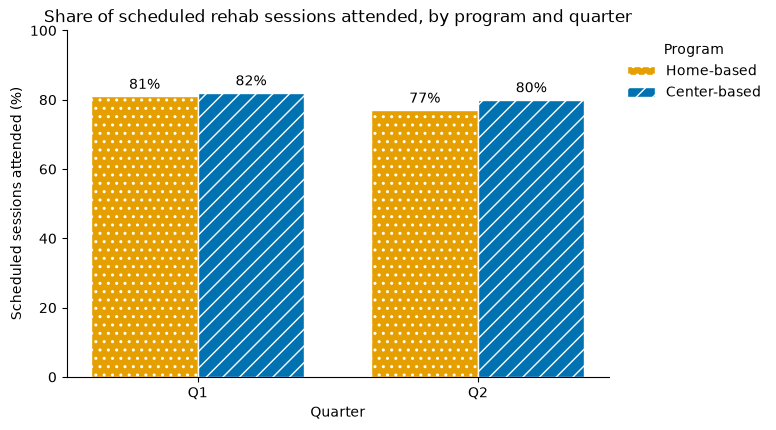

y-axis runs from 0.0 to 100.0


In [7]:
redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))

redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))

home_bars = redesign_ax.bar(x - width / 2, home, width, label="Home-based",
                            color=ORANGE, hatch="..", edgecolor="white")
center_bars = redesign_ax.bar(x + width / 2, center, width, label="Center-based",
                              color=BLUE, hatch="//", edgecolor="white")
for bars in (home_bars, center_bars):
    redesign_ax.bar_label(bars, fmt="%d%%", padding=3)

redesign_ax.set_xticks(x, quarters)
redesign_ax.set_ylim(0, 100)
redesign_ax.set_xlabel("Quarter")
redesign_ax.set_ylabel("Scheduled sessions attended (%)")
redesign_ax.set_title("Share of scheduled rehab sessions attended, by program and quarter")
redesign_ax.spines[["top", "right"]].set_visible(False)
redesign_ax.legend(title="Program", loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)

redesign_fig.savefig(REDESIGN_PATH, dpi=150, bbox_inches="tight")

plt.show()
bottom, top = redesign_ax.get_ylim()
print("y-axis runs from", bottom, "to", top)

## Task 3: Explain one finding to the program coordinator

### 3.1 Write the contract and save the supporting data

> **Checkpoint: `output/explanatory_supporting_data.csv`**
> The header line `program,visit_number,goal_met_pct`, then the eight rows of `data/followup_goals.csv`.

In [8]:
followup = pd.read_csv(FOLLOWUP_PATH)
display(followup)

question = "How does the share of patients meeting the weekly exercise goal change across the four follow-up visits in the home-based and center-based programs?"
audience = "The rehab program coordinator, who will use the chart to decide where to add follow-up support."
intended_claim = "Both programs rose across the four follow-up visits, but center-based patients rose faster, ending at 79% meeting the goal at visit 4 versus 70% for home-based patients."
y_measure = "Percentage of patients seen at that visit who met the weekly goal of 150 minutes of exercise (%)."
grain = "One row of the plotting table, and one point on a line, is one program at one follow-up visit (visit 1 to 4)."
data_types = {
    "program": "categorical", 
    "visit_number": "ordinal",  
    "goal_met_pct": "quantitative",  
}

supporting_data = followup[["program", "visit_number", "goal_met_pct"]]

supporting_data.to_csv(SUPPORTING_DATA_PATH, index=False)

round_trip = pd.read_csv(SUPPORTING_DATA_PATH)
print("shape:", round_trip.shape)
print("same as saved:", round_trip.equals(supporting_data))

,program,visit_number,patients_seen,goal_met_pct
0,Home-based,1,48,58
1,Home-based,2,46,63
2,Home-based,3,45,67
3,Home-based,4,44,70
4,Center-based,1,52,57
5,Center-based,2,50,65
6,Center-based,3,49,72
7,Center-based,4,47,79


shape: (8, 3)
same as saved: True


### 3.2 Draw the explanatory chart

> **Checkpoint: `output/explanatory_chart.png`**
> Your explanatory line chart as a PNG image.

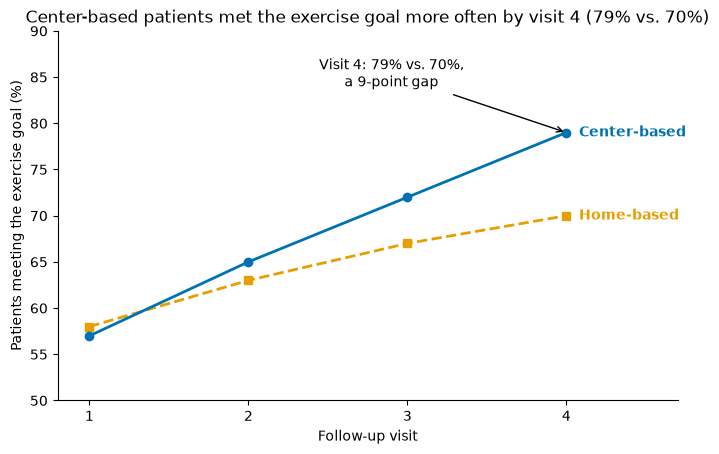

In [9]:
home_goals = supporting_data.loc[supporting_data["program"] == "Home-based"]
center_goals = supporting_data.loc[supporting_data["program"] == "Center-based"]

explanatory_fig, explanatory_ax = plt.subplots(figsize=(8, 4.8))

explanatory_ax.plot(home_goals["visit_number"], home_goals["goal_met_pct"],
                    color=ORANGE, marker="s", linestyle="--", linewidth=2)
explanatory_ax.plot(center_goals["visit_number"], center_goals["goal_met_pct"],
                    color=BLUE, marker="o", linestyle="-", linewidth=2)

# direct labels at the right end of each line
explanatory_ax.text(4.08, 70, "Home-based", color=ORANGE, va="center", fontweight="bold")
explanatory_ax.text(4.08, 79, "Center-based", color=BLUE, va="center", fontweight="bold")

explanatory_ax.annotate(
    "Visit 4: 79% vs. 70%,\na 9-point gap",
    xy=(4, 79), xytext=(2.9, 84),
    arrowprops=dict(arrowstyle="->", color="black"),
    ha="center",
)

explanatory_ax.set_xticks([1, 2, 3, 4])
explanatory_ax.set_xlim(0.8, 4.7)
explanatory_ax.set_ylim(50, 90)
explanatory_ax.set_xlabel("Follow-up visit")
explanatory_ax.set_ylabel("Patients meeting the exercise goal (%)")
explanatory_ax.set_title("Center-based patients met the exercise goal more often by visit 4 (79% vs. 70%)")
explanatory_ax.spines[["top", "right"]].set_visible(False)

explanatory_fig.savefig(EXPLANATORY_PATH, dpi=150, bbox_inches="tight")

plt.show()

### 3.3 Write the text alternative and save the evidence

> **Checkpoint: `output/visualization_evidence.json`**
> The keys `critique`, `question`, `audience`, `intended_claim`, `y_measure`, `grain`, `data_types`, and `text_alternative`.

> **Checkpoint: `output/explanatory_text_alternative.txt`**
> The same paragraph as `text_alternative` in the JSON.

In [10]:
text_alternative = (
    "Line chart of the percentage of patients meeting the weekly exercise goal of 150 minutes "
    "(y-axis, %) at follow-up visits 1 to 4 (x-axis) for two cardiac rehab programs. "
    "Home-based patients (orange dashed line, squares) rose from 58% at visit 1 to 70% at visit 4. "
    "Center-based patients (blue solid line, circles) started similarly at 57% and rose to 79% at visit 4, "
    "a 9-point gap over home-based. Limitation: patients chose their program, so the gap does not show "
    "that one program causes more exercise, and each percentage covers only the patients seen at that "
    "visit, about 45 per program, so a 9-point gap could also come from chance or from which patients returned."
)

visualization_evidence = {
    "critique": critique,
    "question": question,
    "audience": audience,
    "intended_claim": intended_claim,
    "y_measure": y_measure,
    "grain": grain,
    "data_types": data_types,
    "text_alternative": text_alternative,
}

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump(visualization_evidence, file, indent=2, ensure_ascii=False)

with open(TEXT_ALTERNATIVE_PATH, "w", encoding="utf-8") as file:
    file.write(text_alternative)

with open(EVIDENCE_PATH, encoding="utf-8") as file:
    saved = json.load(file)
print(list(saved))

['critique', 'question', 'audience', 'intended_claim', 'y_measure', 'grain', 'data_types', 'text_alternative']


### 3.4 Review the saved charts

Open `output/critique_redesign.png` and `output/explanatory_chart.png`, and answer each question with what you see in them.

1. Printed in grayscale, how would a reader still tell the two programs apart in each chart?
2. Where does the explanatory chart's annotation point, and does its wording stay within what these eight rows can show?
3. Is any text cut off or overlapping in either saved PNG? If so, what did you change?
4. What limitation remains that no chart design can fix?

In the redesign, Home-based bars are dotted and Center-based bars have diagonal stripes, and every bar has its value written on it. In the explanatory chart, Home-based is a dashed line with square markers and Center-based is a solid line with circles, and each line is labeled directly at its right end, so neither chart depends on color.

The arrow points to Center-based's visit-4 point at (4, 79). The text only states the observed values (79% vs. 70%, a 9-point gap) and the title says center-based patients "met the goal more often," which describes the data without claiming the program caused it.

No text is cut off or overlapping in either PNG. The legend in the redesign sits just outside the right edge and bbox_inches="tight" keeps it in the saved file; in the explanatory chart I widened the x-axis to 4.7 so the direct labels fit.

Patients chose their program, so differences could reflect who picked each program rather than the program itself. Each percentage also covers only the roughly 45 patients seen at that visit per program, so the gap could come from chance or from which patients kept returning. No design choice fixes that; it needs randomization or more data.

## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [ ]:
from check_assignment import run_checks

_ = run_checks()